# Sentiment Analysis: Drug Reviews
**Fouzia Khan** | Data Analytics | Oasis Infobyte SIP, Level 1, Task 4

Classify patient drug reviews as positive, neutral or negative. Dataset: UCI Drug Review Dataset (Drugs.com).

## Setup

In [1]:
import html
import re
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from wordcloud import WordCloud

ZIP_PATH = Path("/content/drive/MyDrive/archive.zip")
WORK_DIR = Path("/content/data")
CSV_NAME = "drugsComTrain_raw.csv"
SAMPLE_SIZE = 20_000
SEED = 42

LABELS = ["negative", "neutral", "positive"]
COLORS = {"negative": "#c92a2a", "neutral": "#868e96", "positive": "#2b8a3e"}


def show(data, title="", wrap=None, best=None, precision=2):
    """Display a DataFrame as a styled table. wrap: long text columns, best: columns whose highest value is highlighted."""
    if title:
        display(Markdown(f"**{title}**"))
    styled = (data.style.hide(axis="index").format(precision=precision, na_rep="-")
              .set_table_styles([{"selector": "th", "props": [("background-color", "#1f4e79"),
                                                              ("color", "white"), ("text-align", "left")]}]))
    if best:
        styled = styled.highlight_max(subset=best, props="color: #2b8a3e; font-weight: bold")
    if wrap:
        styled = styled.set_properties(subset=wrap, **{"white-space": "normal", "min-width": "420px", "text-align": "left"})
    display(styled)

## Load Data

In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass  # not running in Colab

csv_path = WORK_DIR / CSV_NAME
if not csv_path.exists():
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extract(CSV_NAME, WORK_DIR)

df_raw = pd.read_csv(csv_path, usecols=["drugName", "condition", "review", "rating"])
show(df_raw.head(), "Raw data (first 5 rows)", wrap=["review"])

Mounted at /content/drive


**Raw data (first 5 rows)**

drugName,condition,review,rating
Valsartan,Left Ventricular Dysfunction,"""It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil""",9
Guanfacine,ADHD,"""My son is halfway through his fourth week of Intuniv. We became concerned when he began this last week, when he started taking the highest dose he will be on. For two days, he could hardly get out of bed, was very cranky, and slept for nearly 8 hours on a drive home from school vacation (very unusual for him.) I called his doctor on Monday morning and she said to stick it out a few days. See how he did at school, and with getting up in the morning. The last two days have been problem free. He is MUCH more agreeable than ever. He is less emotional (a good thing), less cranky. He is remembering all the things he should. Overall his behavior is better. We have tried many different medications and so far this is the most effective.""",8
Lybrel,Birth Control,"""I used to take another oral contraceptive, which had 21 pill cycle, and was very happy- very light periods, max 5 days, no other side effects. But it contained hormone gestodene, which is not available in US, so I switched to Lybrel, because the ingredients are similar. When my other pills ended, I started Lybrel immediately, on my first day of period, as the instructions said. And the period lasted for two weeks. When taking the second pack- same two weeks. And now, with third pack things got even worse- my third period lasted for two weeks and now it's the end of the third week- I still have daily brown discharge. The positive side is that I didn't have any other side effects. The idea of being period free was so tempting... Alas.""",5
Ortho Evra,Birth Control,"""This is my first time using any form of birth control. I'm glad I went with the patch, I have been on it for 8 months. At first It decreased my libido but that subsided. The only downside is that it made my periods longer (5-6 days to be exact) I used to only have periods for 3-4 days max also made my cramps intense for the first two days of my period, I never had cramps before using birth control. Other than that in happy with the patch""",8
Buprenorphine / naloxone,Opiate Dependence,"""Suboxone has completely turned my life around. I feel healthier, I'm excelling at my job and I always have money in my pocket and my savings account. I had none of those before Suboxone and spent years abusing oxycontin. My paycheck was already spent by the time I got it and I started resorting to scheming and stealing to fund my addiction. All that is history. If you're ready to stop, there's a good chance that suboxone will put you on the path of great life again. I have found the side-effects to be minimal compared to oxycontin. I'm actually sleeping better. Slight constipation is about it for me. It truly is amazing. The cost pales in comparison to what I spent on oxycontin.""",9


## 1. Data and Class Distribution
Labels come from the star rating (my rule): 1 to 4 negative, 5 to 6 neutral, 7 to 10 positive. Repeated review texts (about 30%) are removed, so identical texts cannot land in both train and test. A 20,000-review sample keeps the run fast.

**Dataset size**

Step,Rows
Raw reviews,161297
Duplicate review texts removed,48968
Unique reviews,112329
Random sample used,20000


**Class distribution**

Sentiment,Unique reviews,Sample,Sample %
negative,27839,4947,24.73
neutral,9993,1759,8.79
positive,74497,13294,66.47


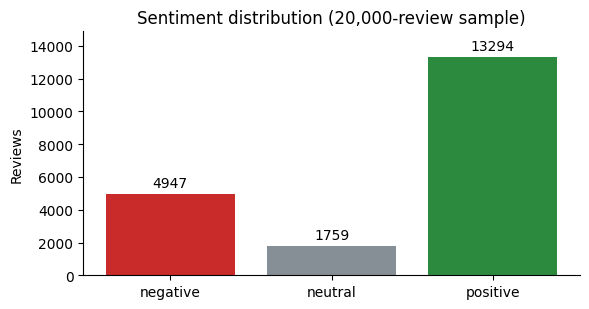

In [3]:
df = df_raw.dropna(subset=["review"]).drop_duplicates(subset="review").reset_index(drop=True)
df["sentiment"] = pd.cut(df["rating"], bins=[0, 4, 6, 10], labels=LABELS).astype(str)
sample = df.sample(SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)

show(pd.DataFrame({
    "Step": ["Raw reviews", "Duplicate review texts removed", "Unique reviews", "Random sample used"],
    "Rows": [len(df_raw), len(df_raw) - len(df), len(df), len(sample)],
}), "Dataset size")

distribution = pd.DataFrame({"Unique reviews": df["sentiment"].value_counts(), "Sample": sample["sentiment"].value_counts()}).reindex(LABELS)
distribution["Sample %"] = distribution["Sample"] / distribution["Sample"].sum() * 100
show(distribution.rename_axis("Sentiment").reset_index(), "Class distribution")

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(LABELS, distribution["Sample"], color=[COLORS[label] for label in LABELS])
ax.bar_label(bars, padding=3)
ax.set_title(f"Sentiment distribution ({len(sample):,}-review sample)")
ax.set_ylabel("Reviews")
ax.set_ylim(0, distribution["Sample"].max() * 1.12)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 2. Text Preprocessing
HTML codes are decoded, text is lowercased and split into words, and stopwords are removed. Negations (not, no, never) are kept, because "not good" means the opposite of "good".

In [4]:
NEGATIONS = {"not", "no", "never", "nor", "cannot", "nothing", "none"}
STOPWORDS = (set(ENGLISH_STOP_WORDS) - NEGATIONS) | {"ve", "ll", "re"}


def clean_text(text):
    """Decode HTML, lowercase, tokenise into words and remove stopwords."""
    text = html.unescape(text).lower().replace("\u2019", "'")
    text = re.sub(r"can't", "cannot", text)
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"n't\b", " not", text)
    tokens = re.findall(r"[a-z]+", text)
    return " ".join(token for token in tokens if len(token) > 1 and token not in STOPWORDS)


sample["clean"] = sample["review"].map(clean_text)

before_after = pd.DataFrame({
    "Original review": sample["review"].head(3).map(lambda t: html.unescape(t).strip('"')[:230] + "..."),
    "After preprocessing": sample["clean"].head(3).map(lambda t: t[:230] + "..."),
})
show(before_after, "Preprocessing example", wrap=["Original review", "After preprocessing"])
print(f"Reviews that became empty after cleaning: {(sample['clean'].str.len() == 0).sum()}")

**Preprocessing example**

Original review,After preprocessing
"Please, anyone with MS, look into Dr. Terry Wahls and her protocol for MS. Most MS symptoms can be controlled through diet. Please take a few minutes to look into this, it could save you a lot of suffering and money....",ms look dr terry wahls protocol ms ms symptoms controlled diet minutes look save lot suffering money...
"I have been on the shot for 6 months now (and am due for my 3rd shot in 2 weeks) and I have yet to get my period! I have had no spotting throughout the 6 months. I do, however, still have the symptoms that I would have if I were t...",shot months rd shot weeks period no spotting months symptoms period time period not bad shot cramps minimal downside huge hypochondriac effects early pregnancy symptoms constantly thinking pregnant chances highly recommend method...
"I, like many others, was having protected sex with my boyfriend when the condom broke. By the time we noticed it, it was too late. Frantic, I jumped in the shower and tried to wash off as best I could. We arrived at Walgreens less...",like having protected sex boyfriend condom broke time noticed late frantic jumped shower tried wash best arrived walgreens hour later took plan pill days queasy able dry heave felt little confident thought meant plan working perio...


Reviews that became empty after cleaning: 0


## 3. TF-IDF and Train/Test Split
**TF-IDF** scores a word by how often it appears in a review multiplied by how rare it is across all reviews, so distinctive words get more weight than common ones. It is fitted on the training set only, to avoid leaking test data.

In [5]:
train_df, test_df = train_test_split(sample, test_size=0.2, stratify=sample["sentiment"], random_state=SEED)
y_train, y_test = train_df["sentiment"], test_df["sentiment"]

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=30_000, sublinear_tf=True)
X_train = vectorizer.fit_transform(train_df["clean"])
X_test = vectorizer.transform(test_df["clean"])

show(pd.DataFrame({
    "Item": ["Training reviews", "Test reviews", "TF-IDF features"],
    "Value": [len(train_df), len(test_df), X_train.shape[1]],
}), "Split and features (80/20, stratified)")

**Split and features (80/20, stratified)**

Item,Value
Training reviews,16000
Test reviews,4000
TF-IDF features,30000


## 4. Models and Evaluation
Naive Bayes and a class-balanced Linear SVM are compared with a baseline that always predicts "positive". Positive reviews dominate, so **macro F1** is the main metric.

In [6]:
BASELINE = "Baseline (always positive)"
NAIVE_BAYES = "Naive Bayes (Multinomial)"
SVM = "Linear SVM (class-balanced)"

classifiers = {
    BASELINE: DummyClassifier(strategy="most_frequent"),
    NAIVE_BAYES: MultinomialNB(),
    SVM: LinearSVC(class_weight="balanced", random_state=SEED),
}

predictions, rows = {}, []
for name, model in classifiers.items():
    predictions[name] = model.fit(X_train, y_train).predict(X_test)
    pred = predictions[name]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
    })
results = pd.DataFrame(rows)
show(results, f"Model comparison on {len(test_df):,} unseen test reviews (higher is better, best in green)",
     best=["Accuracy", "Macro precision", "Macro recall", "Macro F1"], precision=3)


def report_table(y_true, y_pred):
    """Per-class precision, recall and F1 as a table."""
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=LABELS, output_dict=True, zero_division=0)).T
    table = report.loc[LABELS + ["macro avg"], ["precision", "recall", "f1-score", "support"]]
    table["support"] = table["support"].astype(int)
    table = table.rename(index={"macro avg": "Macro average"},
                         columns={"precision": "Precision", "recall": "Recall", "f1-score": "F1-score", "support": "Reviews"})
    return table.rename_axis("Class").reset_index()


for name in (NAIVE_BAYES, SVM):
    show(report_table(y_test, predictions[name]), f"{name}: precision, recall and F1 per class", precision=3)

**Model comparison on 4,000 unseen test reviews (higher is better, best in green)**

Model,Accuracy,Macro precision,Macro recall,Macro F1
Baseline (always positive),0.665,0.222,0.333,0.266
Naive Bayes (Multinomial),0.685,0.522,0.362,0.323
Linear SVM (class-balanced),0.760,0.555,0.550,0.550


**Naive Bayes (Multinomial): precision, recall and F1 per class**

Class,Precision,Recall,F1-score,Reviews
negative,0.887,0.087,0.158,989
neutral,0.000,0.000,0.000,352
positive,0.681,0.999,0.810,2659
Macro average,0.522,0.362,0.323,4000


**Linear SVM (class-balanced): precision, recall and F1 per class**

Class,Precision,Recall,F1-score,Reviews
negative,0.652,0.671,0.661,989
neutral,0.172,0.099,0.126,352
positive,0.843,0.880,0.861,2659
Macro average,0.555,0.550,0.550,4000


### Confusion Matrices

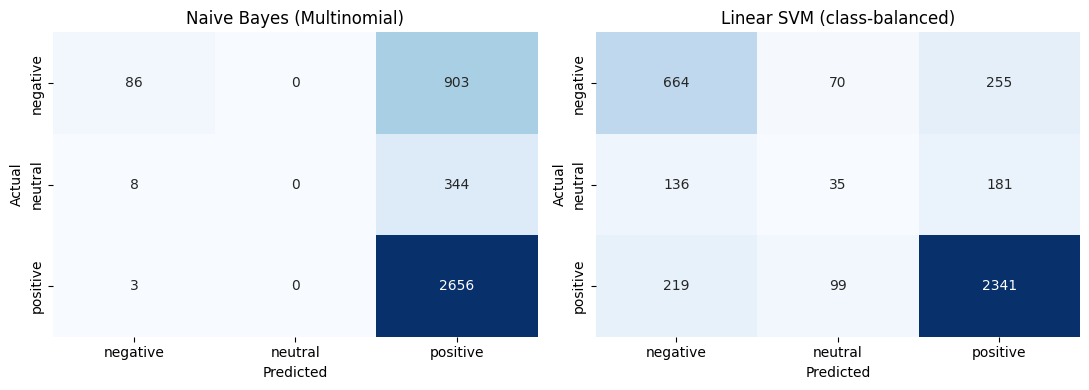

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, (NAIVE_BAYES, SVM)):
    matrix = confusion_matrix(y_test, predictions[name], labels=LABELS)
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 5. Word Clouds
Words that are frequent in all three classes (such as day, week, month) are left out, otherwise the clouds look identical.

Words left out of the clouds (31): anxiety, bad, day, days, did, doctor, effects, feel, got, just, like, medication, mg, month, months, night, no, not, pain, period, pill, started, taking, time, took, week, weeks, weight, went, work, years


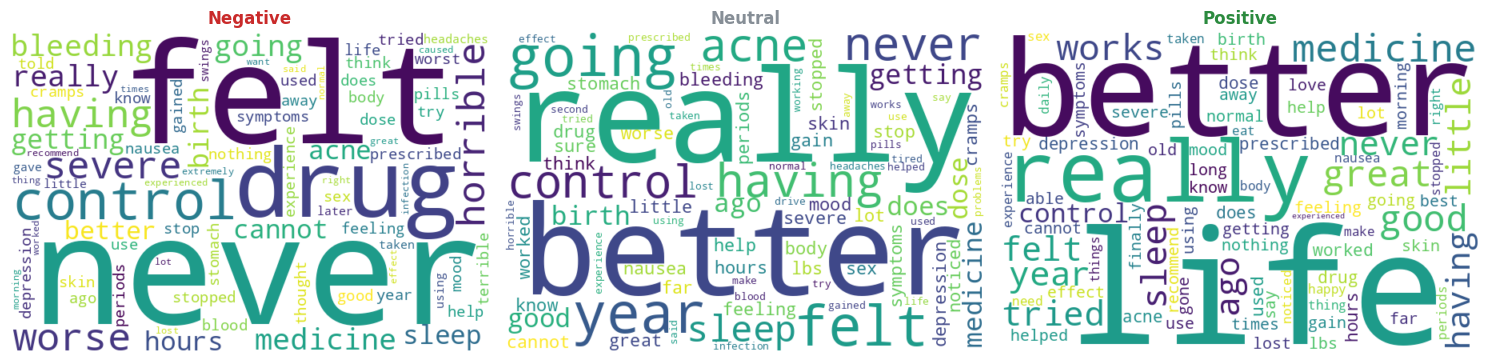

In [8]:
word_counts = {label: Counter(" ".join(sample.loc[sample["sentiment"] == label, "clean"]).split()) for label in LABELS}
shared_words = set.intersection(*[{word for word, _ in counts.most_common(40)} for counts in word_counts.values()])
print(f"Words left out of the clouds ({len(shared_words)}):", ", ".join(sorted(shared_words)))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, label in zip(axes, LABELS):
    frequencies = {word: count for word, count in word_counts[label].items() if word not in shared_words}
    cloud = WordCloud(width=600, height=400, background_color="white", max_words=80, random_state=SEED).generate_from_frequencies(frequencies)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(label.capitalize(), color=COLORS[label], fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Error Analysis
Five random misclassified reviews from the best model.

In [9]:
best_name = results[results["Model"] != BASELINE].sort_values("Macro F1").iloc[-1]["Model"]
errors = test_df.assign(predicted=predictions[best_name])
errors = errors[errors["sentiment"] != errors["predicted"]].sample(5, random_state=SEED)

show(pd.DataFrame({
    "Review": errors["review"].map(lambda t: html.unescape(t).strip('"')[:260] + "..."),
    "Rating": errors["rating"],
    "Actual": errors["sentiment"],
    "Predicted": errors["predicted"],
}), f"5 misclassified reviews ({best_name})", wrap=["Review"])

**5 misclassified reviews (Linear SVM (class-balanced))**

Review,Rating,Actual,Predicted
"I was previously on Lexapro, but it made me tired and unmotivated. I switched to Cymbalta one week ago and it's already working! I'm only on 30 mg but my doc may want me on a higher dose depending on how I feel after a couple weeks....",9,positive,neutral
"I have been on Xanax since 2007 when I was watching my mother slowly suffer. I started on 0.25 mg and eventually the dose was not enough. Now ordered 1 mg in morning and 2 mg at night. It works ,however I have cognitive impairment and all I want to do is sleep...",5,neutral,positive
"I am a long time sufferer of frequent (chronic) migraines, up to 15+ a month. I have used sumatriptan since it became available, both in pill form and self-injection. Yesterday I tried the new patch “Zecuity” for the first time (and likely the last). The actua...",3,negative,positive
"I have bronchitis and was prescribed Cheratussin AC for chest congestion and cough. It might be helping a little with the cough, but it is not bringing up the phlegm. ...",6,neutral,positive
"Sleep very well. Nausea, diarrhea....",8,positive,negative


### What the examples show
- **Rating and text disagree:** an 8-star review describes side effects and stopping the drug, so it is read as negative.
- **Neutral sounds positive:** 6-star reviews that praise parts of the treatment are called positive. Neutral is a narrow band.
- **Mixed experience:** a 2-star review moves from pain to some improvement, which word counts cannot follow.

*Notes refer to the examples of this run (fixed seed).*

## 7. Conclusion

In [10]:
best = results.set_index("Model").loc[best_name]
base_accuracy = results.set_index("Model").loc[BASELINE, "Accuracy"]
nb_accuracy = results.set_index("Model").loc[NAIVE_BAYES, "Accuracy"]
neutral_recall = recall_score(y_test, predictions[best_name], labels=["neutral"], average=None, zero_division=0)[0]

display(Markdown(f"""
- **Best model: {best_name}** (accuracy {best['Accuracy']:.1%}, macro F1 {best['Macro F1']:.2f}). Always predicting "positive" already gives {base_accuracy:.1%}, so accuracy alone misleads.
- **Naive Bayes** (default settings, untuned) reached {nb_accuracy:.1%}, only {(nb_accuracy - base_accuracy) * 100:.1f} points above that baseline: it mostly predicts the majority class.
- **Neutral** is the weak spot: only {neutral_recall:.0%} of neutral reviews are found.
"""))


- **Best model: Linear SVM (class-balanced)** (accuracy 76.0%, macro F1 0.55). Always predicting "positive" already gives 66.5%, so accuracy alone misleads.
- **Naive Bayes** (default settings, untuned) reached 68.5%, only 2.1 points above that baseline: it mostly predicts the majority class.
- **Neutral** is the weak spot: only 10% of neutral reviews are found.


### Real-world use and limits
**Use:** flagging negative patient feedback (for example side-effect complaints) and tracking satisfaction per drug.

**Limits:** labels come from star ratings, results use a 20,000-review sample with one split and no tuning, and the model must not be used for clinical decisions.